In [ ]:
!pip install -q datasets==4.3.0
!pip install -q trl==0.24.0
!pip install -q unsloth
!pip install -q peft accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 14.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 30.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.3/81.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 76.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
else:
    print("No GPU. Runtime > Change runtime type > T4 GPU")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile, shutil

drive.mount('/content/drive')

SRC = Path('/content/drive/MyDrive/manga_task')   # the 5 original files are here
OUT = SRC / 'outputs'                              # everything we save goes here
DATA = Path('/content/data')                       # unzipped dataset (temporary)
OUT.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

if not (DATA / 'development' / 'labels.jsonl').exists():
    for pattern in ['development-*.zip', 'test-*.zip']:
        files = list(SRC.glob(pattern))
        assert files, f'no file matching {pattern} in {SRC}'
        with zipfile.ZipFile(files[0]) as z:
            z.extractall(DATA)
    for name in ['sequences.json', 'sample_submission.jsonl', 'score.py']:
        shutil.copy(SRC / name, DATA / name)

print(sorted(p.name for p in DATA.iterdir()))

Mounted at /content/drive
['development', 'sample_submission.jsonl', 'score.py', 'sequences.json', 'test']


In [ ]:
#inspecting dataset
import json, collections
from PIL import Image

seqs = json.load(open(DATA / 'sequences.json'))
rows = [json.loads(l) for l in open(DATA / 'development' / 'labels.jsonl') if l.strip()]
labels = {r['sequence_id']: r['pages'] for r in rows}      # sequence id -> list of 3 pages
test_ids = [json.loads(l)['sequence_id'] for l in open(DATA / 'sample_submission.jsonl') if l.strip()]
seq_by_id = {s['sequence_id']: s for s in seqs}

print('sequences.json entries:', len(seqs), collections.Counter(s['split'] for s in seqs))
print('labelled dev sequences:', len(labels), '| test ids:', len(test_ids))

missing = [p for s in seqs for p in s['images'] if not (DATA / p).exists()]
print('missing image files:', len(missing))
dev_ids = {s['sequence_id'] for s in seqs if s['split'] == 'development'}
print('dev ids == label ids:', dev_ids == set(labels))
print('test ids == submission ids:', {s['sequence_id'] for s in seqs if s['split'] == 'test'} == set(test_ids))

n_pages = sum(len(p) for p in labels.values())
n_lines = sum(len(page) for pages in labels.values() for page in pages)
n_empty = sum(1 for pages in labels.values() for page in pages if not page)
speakers = collections.Counter(x['speaker'] for pages in labels.values() for page in pages for x in page)
print(f'pages: {n_pages} | text lines: {n_lines} | empty pages: {n_empty}')
print('speaker counts:', speakers.most_common())

sequences.json entries: 95 Counter({'development': 80, 'test': 15})
labelled dev sequences: 80 | test ids: 15
missing image files: 0
dev ids == label ids: True
test ids == submission ids: True
pages: 240 | text lines: 1753 | empty pages: 10
speaker counts: [('character1', 657), ('character2', 531), ('character3', 261), ('character4', 109), ('NARRATION', 76), ('character5', 57), ('UNKNOWN', 34), ('character6', 23), ('character7', 3), ('character8', 2)]


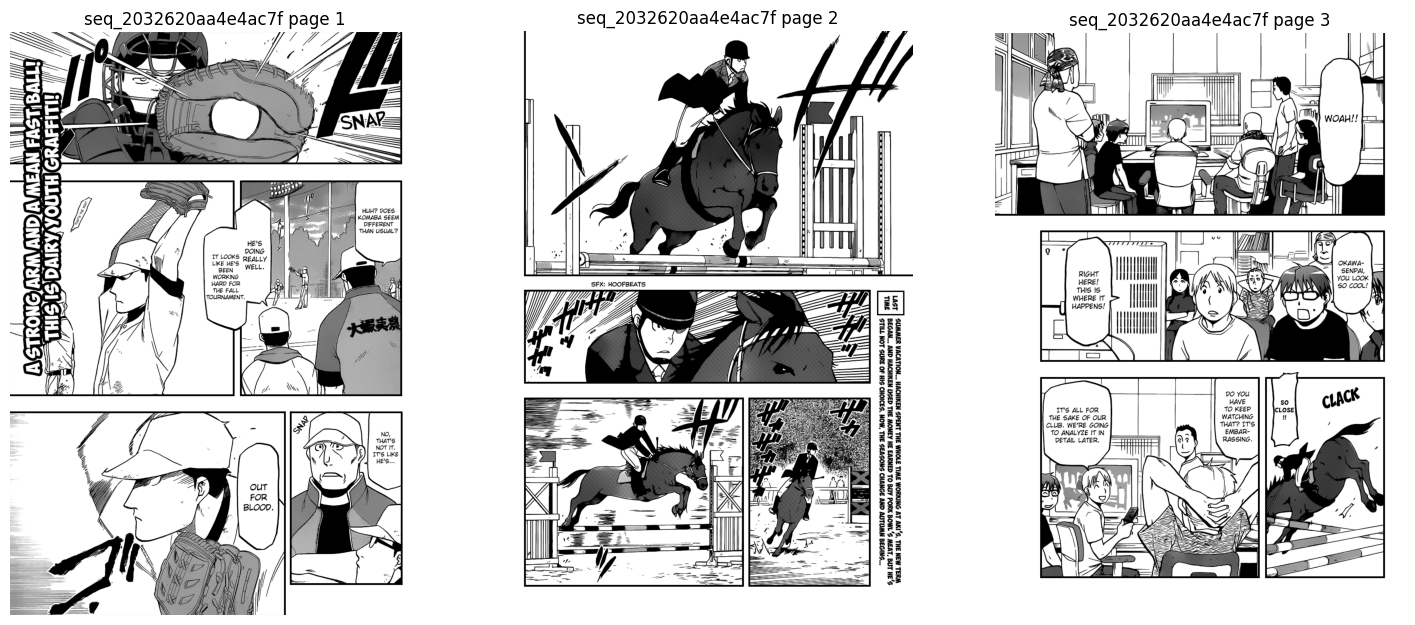

--- page 1 (5 lines) ---
  [character1] HUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?
  [character2] HE'S DOING REALLY WELL. IT LOOKS LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT.
  [UNKNOWN] THAT'S THE WAY!
  [character1] NO, THAT'S NOT IT. IT'S LIKE HE'S...
  [character1] OUT FOR BLOOD.
--- page 2 (0 lines) ---
--- page 3 (6 lines) ---
  [UNKNOWN] WOAH!!
  [character3] OKAWA-SENPAI, YOU LOOK SO COOL!
  [character4] RIGHT HERE! THIS IS WHERE IT HAPPENS!
  [UNKNOWN] SO CLOSE!!
  [character5] DO YOU HAVE TO KEEP WATCHING THAT? IT'S EMBARRASSING.
  [character4] IT'S ALL FOR THE SAKE OF OUR CLUB. WE'RE GOING TO ANALYZE IT IN DETAIL LATER.


In [ ]:
import matplotlib.pyplot as plt

def show_sequence(sid):
    fig, axes = plt.subplots(1, 3, figsize=(18, 9))
    for i, (ax, rel) in enumerate(zip(axes, seq_by_id[sid]['images'])):
        ax.imshow(Image.open(DATA / rel).convert('RGB'))
        ax.set_title(f'{sid} page {i+1}')
        ax.axis('off')
    plt.show()
    for i, page in enumerate(labels[sid], 1):
        print(f'--- page {i} ({len(page)} lines) ---')
        for row in page:
            print(f"  [{row['speaker']}] {row['text']}")

dev_list = [s['sequence_id'] for s in seqs if s['split'] == 'development']
show_sequence(dev_list[0])

In [ ]:
#splitting into train and validation data
import random

SEED, VAL_FRAC = 42, 0.2
ids = sorted(labels)
random.Random(SEED).shuffle(ids)
n_val = round(len(ids) * VAL_FRAC)
val_ids, train_ids = sorted(ids[:n_val]), sorted(ids[n_val:])
assert not set(train_ids) & set(val_ids), 'LEAKAGE: overlap between train and val'

json.dump({'seed': SEED, 'train': train_ids, 'val': val_ids}, open(OUT / 'split.json', 'w'), indent=2)

def write_jsonl(path, items):
    with open(path, 'w', encoding='utf-8') as f:
        for item in items:
            f.write(json.dumps(item, ensure_ascii=False) + '\n')

# score.py needs a reference file with exactly the sequences being scored
row_by_id = {r['sequence_id']: r for r in rows}
write_jsonl(OUT / 'train_labels.jsonl', [row_by_id[i] for i in train_ids])
write_jsonl(OUT / 'val_labels.jsonl', [row_by_id[i] for i in val_ids])
print(len(train_ids), 'train |', len(val_ids), 'val')

64 train | 16 val


In [ ]:
import subprocess, sys

def run_scorer(refs, preds, out_json):
    r = subprocess.run([sys.executable, str(DATA / 'score.py'), '--references', str(refs),
                        '--predictions', str(preds), '--output', str(out_json)],
                       capture_output=True, text=True)
    print(r.stdout or r.stderr)

perfect = Path('/content/val_perfect.jsonl')
perfect.write_text((OUT / 'val_labels.jsonl').read_text(encoding='utf-8'), encoding='utf-8')
print('PERFECT:')
run_scorer(OUT / 'val_labels.jsonl', perfect, '/content/perfect_scores.json')

empty = Path('/content/val_empty.jsonl')
write_jsonl(empty, [{'sequence_id': s, 'pages': [[], [], []]} for s in val_ids])
print('EMPTY:')
run_scorer(OUT / 'val_labels.jsonl', empty, '/content/empty_scores.json')

PERFECT:
{
  "text_order_score": 1.0,
  "balanced_joint_f1": 1.0,
  "speaker_accuracy_on_matched": 1.0,
  "joint_f1": 1.0,
  "matched_token_coverage": 1.0
}

EMPTY:
{
  "text_order_score": 0.0,
  "balanced_joint_f1": 0.0,
  "speaker_accuracy_on_matched": 0.0,
  "joint_f1": 0.0,
  "matched_token_coverage": 0.0
}



In [ ]:
#loading base model
from unsloth import FastVisionModel
import torch

model, tokenizer = FastVisionModel.from_pretrained(
    "unsloth/Qwen2-VL-7B-Instruct",
    load_in_4bit=True,                     # fits on the T4
    use_gradient_checkpointing="unsloth",  # saves VRAM when we train later
)
FastVisionModel.for_inference(model)       # generation mode
print("VRAM (GB):", round(torch.cuda.memory_allocated() / 1024**3, 2))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.9.14: Fast Qwen2_Vl patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

Unsloth: Offloading embeddings to RAM to save 1.02 GB.
VRAM (GB): 5.38


In [ ]:
import re

PROMPT_V1 = """You are transcribing one page of an English manga.
Extract ONLY the story text and answer with JSON.

INCLUDE: speech balloons, thought balloons, narration/caption boxes, clear spoken screams or grunts (e.g. "AAGH!"), and balloons that contain only punctuation (e.g. "...", "?!").
EXCLUDE: sound effects drawn as art (e.g. SNAP, BAM), titles, logos, credits, page numbers, ads, watermarks, translator or editor notes, text on signs, clothes or objects, and text shown on screens or documents.

ORDER: Order the lines the way a reader would read the page: manga is read right-to-left, top-to-bottom.
Put the text of one balloon in one line.

SPEAKERS: give each line a speaker label. Use character1, character2, ... in order of first appearance on this page; the same person always gets the same label. Use NARRATION for narration boxes. Use UNKNOWN if you cannot tell who speaks.

OUTPUT: only JSON, no explanation, in exactly this form:
{"lines": [{"speaker": "character1", "text": "..."}]}
If the page has no story text, answer {"lines": []}."""


def run_vlm(img, prompt, max_new_tokens=1024):
    # the {'type': 'image'} entry marks where the picture goes; the picture itself is passed to the tokenizer
    messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': prompt}]}]
    text = tokenizer.apply_chat_template(messages, add_generation_prompt=True)
    inputs = tokenizer(img, text, add_special_tokens=False, return_tensors='pt').to('cuda')
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True)
    # cut off the prompt tokens, keep only the answer
    return tokenizer.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)[0]


def parse_model_output(raw):
    raw = raw.replace("```json", "").replace("```", "")
    try:
        items = json.loads(raw[raw.find("{"): raw.rfind("}") + 1])["lines"]
    except (ValueError, KeyError):
        # output was cut off or broken: pick out the complete speaker/text pairs
        found = re.findall(r'"speaker":\s*"([^"]*)",\s*"text":\s*"([^"]*)"', raw)
        items = [{"speaker": s, "text": t} for s, t in found]
    # the scorer rejects empty speaker or text, so drop those lines
    return [{"speaker": i["speaker"].strip(), "text": i["text"].strip()}
            for i in items if i["speaker"].strip() and i["text"].strip()]


def process_sequence(seq, prompt):
    pages, raws = [], []
    for rel in seq['images']:                      # page 1, 2, 3 in order
        img = Image.open(DATA / rel).convert('RGB')
        raw = run_vlm(img, prompt)
        pages.append(parse_model_output(raw))
        raws.append(raw)
    return pages, raws


# parser self-test (no GPU needed)
assert parse_model_output('{"lines": []}') == []
assert len(parse_model_output('```json\n{"lines":[{"speaker":"character1","text":"Hi"}]}\n```')) == 1
assert len(parse_model_output('{"lines":[{"speaker":"character1","text":"Hi"},{"speaker":"character2","text":"Yo')) == 1
print('parser tests passed')

parser tests passed


In [ ]:
def show_compare(sid, pages):
    for i in range(3):
        print(f'===== PAGE {i+1} =====')
        print('PREDICTED:')
        for r in pages[i]: print(f"  [{r['speaker']}] {r['text']}")
        print('GROUND TRUTH:')
        for r in labels[sid][i]: print(f"  [{r['speaker']}] {r['text']}")

sid = val_ids[0]
pages, raws = process_sequence(seq_by_id[sid], PROMPT_V1)
show_compare(sid, pages)

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cuda' is deprecated, please use 'torch.backends.cuda.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cudnn' is deprecated, please use 'torch.backends.cudnn.is_available()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_mkldnn' is deprecated, please use 'torch.backends.mkldnn.is_available()'
  return original(name)
Both `max_new_tokens` (=102

===== PAGE 1 =====
PREDICTED:
  [NARRATION] A STRONG ARM AND A MEAN FASTBALL! THIS IS DAIYOUTH CRAFT!!
  [NARRATION] SNAP
  [NARRATION] HUUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?
  [NARRATION] IT LOOKS LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT.
  [NARRATION] HE'S DOING REALLY WELL.
  [NARRATION] SNAP
  [NARRATION] NO, THAT'S NOT IT. IT'S LIKE HE'S...
  [NARRATION] OUT FOR BLOOD.
GROUND TRUTH:
  [character1] HUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?
  [character2] HE'S DOING REALLY WELL. IT LOOKS LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT.
  [UNKNOWN] THAT'S THE WAY!
  [character1] NO, THAT'S NOT IT. IT'S LIKE HE'S...
  [character1] OUT FOR BLOOD.
===== PAGE 2 =====
PREDICTED:
  [NARRATION] LAST TIME SUMMER VACATION... HACHIKEN SPENT THE WHOLE TIME WORKING AT AKI'S. THE NEW TERM BEGAN... AND HACHIKEN USED THE MONEY HE EARNED TO BUY PORK BOWL'S MEAT. BUT HE'S STILL NOT SURE OF HIS CHOICES. NOW, THE SEASONS CHANGE AND AUTUMN BEGINS...
  [NARRATION] SFX: HOOFBEATS
  

In [ ]:
import csv, time

def run_experiment(exp, prompt, pipeline, training='none (frozen)', notes=''):
    pred_path = OUT / f'{exp}_predictions.jsonl'
    raw_path = OUT / f'{exp}_raw.jsonl'
    (OUT / 'prompts').mkdir(exist_ok=True)
    (OUT / 'prompts' / f'{exp}.txt').write_text(prompt, encoding='utf-8')

    done = set()
    if pred_path.exists():
        done = {json.loads(l)['sequence_id'] for l in open(pred_path) if l.strip()}
    todo = [s for s in val_ids if s not in done]
    print(f'{exp}: {len(done)} done, {len(todo)} to do')

    start = time.time()
    for n, sid in enumerate(todo, 1):
        try:
            pages, raws = process_sequence(seq_by_id[sid], prompt)
        except Exception as e:
            print('FAILED', sid, e)
            torch.cuda.empty_cache()
            continue                                # not saved, so it is retried next run
        with open(pred_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps({'sequence_id': sid, 'pages': pages}, ensure_ascii=False) + '\n')
        with open(raw_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps({'sequence_id': sid, 'raw': raws}, ensure_ascii=False) + '\n')
        print(f'[{n}/{len(todo)}] {sid} lines per page={[len(p) for p in pages]} ({(time.time()-start)/60:.1f} min)')

    score_path = OUT / f'{exp}_scores.json'
    run_scorer(OUT / 'val_labels.jsonl', pred_path, score_path)
    m = json.load(open(score_path))['macro']

    log = OUT / 'experiments.csv'
    is_new = not log.exists()
    fmt = lambda v: '' if v is None else round(v, 4)
    with open(log, 'a', newline='', encoding='utf-8') as f:
        w = csv.writer(f)
        if is_new:
            w.writerow(['experiment', 'pipeline', 'training', 'text_order', 'joint_f1',
                        'balanced_joint_f1', 'speaker_acc_matched', 'coverage', 'notes'])
        w.writerow([exp, pipeline, training, fmt(m['text_order_score']), fmt(m['joint_f1']),
                    fmt(m['balanced_joint_f1']), fmt(m['speaker_accuracy_on_matched']),
                    fmt(m['matched_token_coverage']), notes])


run_experiment('A_baseline_v1', PROMPT_V1, 'Qwen2-VL-7B 4bit, page-by-page JSON prompt v1')

import pandas as pd
pd.read_csv(OUT / 'experiments.csv')

A_baseline_v1: 16 done, 0 to do
{
  "text_order_score": 0.5506407169874427,
  "balanced_joint_f1": 0.1794715025231991,
  "speaker_accuracy_on_matched": 0.49597350680865515,
  "joint_f1": 0.32455571997842425,
  "matched_token_coverage": 0.6571246471734332
}



,experiment,pipeline,training,text_order,joint_f1,balanced_joint_f1,speaker_acc_matched,coverage,notes
0,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
1,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A
2,B_prompt_v2,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v2",none (frozen),0.5674,0.3587,0.2202,0.5586,0.6789,excludes SFX/tagline/recap; NARRATION only for...
3,B_prompt_v2_keep1,B_prompt_v2 + keep at most 1 copy of the same ...,none (frozen),0.5671,0.3672,0.2209,0.5567,0.6754,same raw output as B_prompt_v2
4,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN


In [ ]:
raw_a = {}
for l in open(OUT / 'A_baseline_v1_raw.jsonl'):
    r = json.loads(l)
    raw_a[r['sequence_id']] = r['raw']

for sid, page_idx in [('seq_5f9ee35846b7e635', 1), ('seq_b9b5a9ad9a64ced9', 0)]:
    raw = raw_a[sid][page_idx]
    texts = [x['text'] for x in parse_model_output(raw)]
    print(sid, 'page', page_idx + 1, '| lines:', len(texts),
          '| unique texts:', len(set(texts)), '| gold lines:', len(labels[sid][page_idx]))
    print(raw[:500])
    print('...')
    print(raw[-300:])
    print()

seq_5f9ee35846b7e635 page 2 | lines: 73 | unique texts: 5 | gold lines: 5
{"lines": [{"speaker": "character1", "text": "NO, ESPECIALLY BECAUSE HE IS A CRIMINAL?"}, {"speaker": "character2", "text": "ACCEPT A MAN EVEN IF ..."}, {"speaker": "NARRATION", "text": "MUSTN'T WE, AS FOLLOWERS OF BUDDHA, ..."}, {"speaker": "character1", "text": "..."}, {"speaker": "NARRATION", "text": "..."}, {"speaker": "character1", "text": "!"}, {"speaker": "NARRATION", "text": "!"}, {"speaker": "character1", "text": "!"}, {"speaker": "NARRATION", "text": "!"}, {"speaker": "character1", "te
...
text": "!"}, {"speaker": "NARRATION", "text": "!"}, {"speaker": "character1", "text": "!"}, {"speaker": "NARRATION", "text": "!"}, {"speaker": "character1", "text": "!"}, {"speaker": "NARRATION", "text": "!"}, {"speaker": "character1", "text": "!"}, {"speaker": "NARRATION", "text": "!"}, {"speaker":

seq_b9b5a9ad9a64ced9 page 1 | lines: 40 | unique texts: 7 | gold lines: 5
```json
{
  "lines": [
    {
      "speaker":

measure repitition on all 48 pages


---



In [ ]:
rep = []
for l in open(OUT / 'A_baseline_v1_raw.jsonl'):
    r = json.loads(l)
    for i, raw in enumerate(r['raw']):
        texts = [x['text'] for x in parse_model_output(raw)]
        cut_off = not raw.rstrip().rstrip('`').rstrip().endswith('}')   # JSON did not finish
        rep.append([r['sequence_id'], i + 1, len(texts), len(set(texts)),
                    len(labels[r['sequence_id']][i]), cut_off])

df = pd.DataFrame(rep, columns=['sequence', 'page', 'lines', 'unique_texts', 'gold_lines', 'cut_off'])
df['repeated'] = df['lines'] - df['unique_texts']
print('repeated lines in total:', df['repeated'].sum(), 'of', df['lines'].sum())
print('pages whose JSON was cut off:', df['cut_off'].sum())
display(df.sort_values('repeated', ascending=False).head(8))

repeated lines in total: 104 of 430
pages whose JSON was cut off: 2


,sequence,page,lines,unique_texts,gold_lines,cut_off,repeated
7,seq_5f9ee35846b7e635,2,73,5,5,True,68
27,seq_b9b5a9ad9a64ced9,1,40,7,5,True,33
9,seq_84541a1f4b159018,1,16,15,11,False,1
0,seq_2032620aa4e4ac7f,1,8,7,5,False,1
26,seq_b8b5563330fdc89d,3,8,7,8,False,1
4,seq_45c9871f52e99417,2,7,7,7,False,0
3,seq_45c9871f52e99417,1,8,8,8,False,0
2,seq_2032620aa4e4ac7f,3,7,7,6,False,0


Experiment-A2 (post-processing only, same model output)

In [ ]:
MAX_COPIES = 1
EXP_NAME = f'A2_keep{MAX_COPIES}'

a2_rows = []
for l in open(OUT / 'A_baseline_v1_raw.jsonl'):
    r = json.loads(l)
    pages = []
    for raw in r['raw']:
        count, kept = {}, []
        for line in parse_model_output(raw):
            count[line['text']] = count.get(line['text'], 0) + 1
            if count[line['text']] <= MAX_COPIES:
                kept.append(line)
        pages.append(kept)
    a2_rows.append({'sequence_id': r['sequence_id'], 'pages': pages})

write_jsonl(OUT / f'{EXP_NAME}_predictions.jsonl', a2_rows)
run_scorer(OUT / 'val_labels.jsonl', OUT / f'{EXP_NAME}_predictions.jsonl', OUT / f'{EXP_NAME}_scores.json')

m = json.load(open(OUT / f'{EXP_NAME}_scores.json'))['macro']
with open(OUT / 'experiments.csv', 'a', newline='', encoding='utf-8') as f:
    csv.writer(f).writerow([EXP_NAME, f'A + keep at most {MAX_COPIES} copy of the same text per page',
                            'none (frozen)', round(m['text_order_score'], 4), round(m['joint_f1'], 4),
                            round(m['balanced_joint_f1'], 4), round(m['speaker_accuracy_on_matched'], 4),
                            round(m['matched_token_coverage'], 4), 'same raw output as A'])
pd.read_csv(OUT / 'experiments.csv')

{
  "text_order_score": 0.5644585555153543,
  "balanced_joint_f1": 0.1810752494747126,
  "speaker_accuracy_on_matched": 0.4969336945837075,
  "joint_f1": 0.33764290219764065,
  "matched_token_coverage": 0.6561246471734332
}



,experiment,pipeline,training,text_order,joint_f1,balanced_joint_f1,speaker_acc_matched,coverage,notes
0,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
1,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A
2,B_prompt_v2,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v2",none (frozen),0.5674,0.3587,0.2202,0.5586,0.6789,excludes SFX/tagline/recap; NARRATION only for...
3,B_prompt_v2_keep1,B_prompt_v2 + keep at most 1 copy of the same ...,none (frozen),0.5671,0.3672,0.2209,0.5567,0.6754,same raw output as B_prompt_v2
4,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
5,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A


In [ ]:
PROMPT_V2 = """You are transcribing one page of an English manga. Extract ONLY the story text and answer with JSON.

INCLUDE:
- speech balloons and thought balloons
- narration boxes (plain rectangular caption boxes that narrate the story)
- clear spoken screams, grunts or vocalisations
- balloons that contain only punctuation, such as "..." or "?!"

EXCLUDE (never output these):
- sound effects, even in English letters (SNAP, CLACK, BAM)
- translator captions such as "SFX: ..." and editor or scanlator notes
- large decorative taglines or titles along panel edges
- "last time" recap or summary boxes
- page numbers, credits, logos, ads, watermarks
- text on signs, clothes, objects, screens or documents

ORDER: manga is read right-to-left, top-to-bottom. Read panels from the top-right to the bottom-left. In a balloon with several vertical text columns, read the rightmost column first. One balloon = one line.

SPEAKERS: give each balloon the label of the character who says it: character1, character2, ... numbered in order of first appearance on this page; the same person always keeps the same label. Use NARRATION ONLY for rectangular narration boxes, never for balloons that a character speaks. Use UNKNOWN if the speaker is off-panel or unclear.

Do not repeat any line. If the page has no story text, answer {"lines": []}.

OUTPUT only JSON, exactly in this form:
{"lines": [{"speaker": "character1", "text": "..."}]}"""

pages, raws = process_sequence(seq_by_id[val_ids[0]], PROMPT_V2)
show_compare(val_ids[0], pages)

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


===== PAGE 1 =====
PREDICTED:
  [unknown] A STRONG ARM AND A MEAN FASTBALL! THIS IS DAIYOUTH CRAFT!!
  [unknown] SNAP
  [unknown] Huh? Does Komaba seem different than usual?
  [unknown] It looks like he's been working hard for the fall tournament.
  [unknown] He's doing really well.
  [unknown] Out for blood.
  [unknown] No, that's not it. It's like he's...
GROUND TRUTH:
  [character1] HUH? DOES KOMABA SEEM DIFFERENT THAN USUAL?
  [character2] HE'S DOING REALLY WELL. IT LOOKS LIKE HE'S BEEN WORKING HARD FOR THE FALL TOURNAMENT.
  [UNKNOWN] THAT'S THE WAY!
  [character1] NO, THAT'S NOT IT. IT'S LIKE HE'S...
  [character1] OUT FOR BLOOD.
===== PAGE 2 =====
PREDICTED:
  [Hachiken] SUMMER VACATION... HACHIKEN SPENT THE WHOLE TIME WORKING AT AKI'S. THE NEW TERM BEGAN... AND HACHIKEN USED THE MONEY HE EARNED TO BUY PORK BOWL'S MEAT. BUT HE'S STILL NOT SURE OF HIS CHOICES. NOW, THE SEASONS CHANGE AND AUTUMN BEGINS...
  [Hachiken] LAST TIME
  [Hachiken] BEGAN... AND HACHIKEN USED THE MONEY HE 

In [ ]:
run_experiment('B_prompt_v2', PROMPT_V2, 'Qwen2-VL-7B 4bit, page-by-page JSON prompt v2',
               notes='excludes SFX/tagline/recap; NARRATION only for boxes; right-to-left order')
pd.read_csv(OUT / 'experiments.csv')

B_prompt_v2: 16 done, 0 to do
{
  "text_order_score": 0.5674000323843158,
  "balanced_joint_f1": 0.22019508070723187,
  "speaker_accuracy_on_matched": 0.5586342016885638,
  "joint_f1": 0.3587041974767839,
  "matched_token_coverage": 0.6788774027294198
}



,experiment,pipeline,training,text_order,joint_f1,balanced_joint_f1,speaker_acc_matched,coverage,notes
0,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
1,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A
2,B_prompt_v2,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v2",none (frozen),0.5674,0.3587,0.2202,0.5586,0.6789,excludes SFX/tagline/recap; NARRATION only for...
3,B_prompt_v2_keep1,B_prompt_v2 + keep at most 1 copy of the same ...,none (frozen),0.5671,0.3672,0.2209,0.5567,0.6754,same raw output as B_prompt_v2
4,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
5,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A
6,B_prompt_v2,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v2",none (frozen),0.5674,0.3587,0.2202,0.5586,0.6789,excludes SFX/tagline/recap; NARRATION only for...


In [ ]:
def compare(exp_a, exp_b, metric):
    sa = json.load(open(OUT / f'{exp_a}_scores.json'))['sequences']
    sb = json.load(open(OUT / f'{exp_b}_scores.json'))['sequences']
    better = worse = same = 0
    for sid in sa:
        a, b = sa[sid][metric], sb[sid][metric]
        if a is None or b is None:
            continue
        if b > a + 0.01: better += 1
        elif b < a - 0.01: worse += 1
        else: same += 1
    print(f'{metric}: B better on {better}, worse on {worse}, about equal on {same} sequences')

for m in ['text_order_score', 'joint_f1', 'balanced_joint_f1']:
    compare('A_baseline_v1', 'B_prompt_v2', m)

text_order_score: B better on 6, worse on 6, about equal on 4 sequences
joint_f1: B better on 7, worse on 6, about equal on 3 sequences
balanced_joint_f1: B better on 10, worse on 5, about equal on 1 sequences


In [ ]:
import re, csv
from collections import Counter

def rescore_with_dedupe(exp, max_copies=1):
    """Same raw model output, but keep at most max_copies of the same text per page."""
    name = f'{exp}_keep{max_copies}'
    if (OUT / f'{name}_scores.json').exists():
        print(name, 'already done, skipping')
        return
    out_rows = []
    for l in open(OUT / f'{exp}_raw.jsonl'):
        r = json.loads(l)
        pages = []
        for raw in r['raw']:
            count, kept = {}, []
            for line in parse_model_output(raw):
                count[line['text']] = count.get(line['text'], 0) + 1
                if count[line['text']] <= max_copies:
                    kept.append(line)
            pages.append(kept)
        out_rows.append({'sequence_id': r['sequence_id'], 'pages': pages})
    write_jsonl(OUT / f'{name}_predictions.jsonl', out_rows)
    run_scorer(OUT / 'val_labels.jsonl', OUT / f'{name}_predictions.jsonl', OUT / f'{name}_scores.json')
    m = json.load(open(OUT / f'{name}_scores.json'))['macro']
    with open(OUT / 'experiments.csv', 'a', newline='', encoding='utf-8') as f:
        csv.writer(f).writerow([name, f'{exp} + keep at most {max_copies} copy of the same text per page',
                                'same as ' + exp, round(m['text_order_score'], 4), round(m['joint_f1'], 4),
                                round(m['balanced_joint_f1'], 4), round(m['speaker_accuracy_on_matched'], 4),
                                round(m['matched_token_coverage'], 4), f'same raw output as {exp}'])


def repetition_report(exp):
    rep_rows = []
    for l in open(OUT / f'{exp}_raw.jsonl'):
        r = json.loads(l)
        for i, raw in enumerate(r['raw']):
            texts = [x['text'] for x in parse_model_output(raw)]
            cut_off = not raw.rstrip().rstrip('`').rstrip().endswith('}')   # JSON did not finish
            rep_rows.append([r['sequence_id'], i + 1, len(texts), len(set(texts)),
                             len(labels[r['sequence_id']][i]), cut_off])
    df = pd.DataFrame(rep_rows, columns=['sequence', 'page', 'lines', 'unique_texts', 'gold_lines', 'cut_off'])
    df['repeated'] = df['lines'] - df['unique_texts']
    print(exp, '| repeated lines:', df['repeated'].sum(), 'of', df['lines'].sum(),
          '| pages cut off:', df['cut_off'].sum())
    return df.sort_values('repeated', ascending=False).head(8)


def compare(exp_a, exp_b, metric):
    sa = json.load(open(OUT / f'{exp_a}_scores.json'))['sequences']
    sb = json.load(open(OUT / f'{exp_b}_scores.json'))['sequences']
    better = worse = same = 0
    for sid in sa:
        a, b = sa[sid][metric], sb[sid][metric]
        if a is None or b is None:
            continue
        if b > a + 0.01: better += 1
        elif b < a - 0.01: worse += 1
        else: same += 1
    print(f'{metric}: {exp_b} better on {better}, worse on {worse}, about equal on {same} sequences')


def words(page):
    return re.findall(r"[a-z0-9']+", ' '.join(x['text'] for x in page).lower())

def bag_f1(gold_page, pred_page):
    g, p = Counter(words(gold_page)), Counter(words(pred_page))
    if not g and not p:
        return None
    overlap = sum((g & p).values())
    if overlap == 0:
        return 0.0
    prec, rec = overlap / sum(p.values()), overlap / sum(g.values())
    return 2 * prec * rec / (prec + rec)

def bag_vs_order(exp):
    """Order-free word overlap vs the scorer's page score: is the problem order, or the words themselves?"""
    preds = {}
    for l in open(OUT / f'{exp}_predictions.jsonl'):
        r = json.loads(l)
        preds[r['sequence_id']] = r['pages']
    scores = json.load(open(OUT / f'{exp}_scores.json'))['sequences']
    bag, order = [], []
    for sid, pages in preds.items():
        for i in range(3):
            b = bag_f1(labels[sid][i], pages[i])
            if b is None:
                continue
            bag.append(b)
            order.append(scores[sid]['page_text_scores'][str(i + 1)])
    print(exp, '| pages with text:', len(bag))
    print('  order-free word F1:', round(sum(bag) / len(bag), 3))
    print('  scorer page score :', round(sum(order) / len(order), 3))

In [ ]:
EXP = 'C_lora_v2prompt'
preds = {}
for l in open(OUT / f'{EXP}_predictions.jsonl'):
    r = json.loads(l)
    preds[r['sequence_id']] = r['pages']

def one_plain_word(text):
    return len(text.split()) == 1 and text.isalpha()

wrongly_filled = missed_page = 0
pred_lines = gold_lines = pred_narr = gold_narr = pred_oneword = gold_oneword = 0
for sid, pred_pages in preds.items():
    for g, p in zip(labels[sid], pred_pages):
        wrongly_filled += (not g) and bool(p)        # gold page empty, we predicted text
        missed_page += bool(g) and (not p)           # gold page has text, we predicted nothing
        pred_lines += len(p); gold_lines += len(g)
        pred_narr += sum(x['speaker'] == 'NARRATION' for x in p)
        gold_narr += sum(x['speaker'] == 'NARRATION' for x in g)
        pred_oneword += sum(one_plain_word(x['text']) for x in p)
        gold_oneword += sum(one_plain_word(x['text']) for x in g)

print(f'{EXP}: {len(preds)} sequences')
print('empty gold pages that we filled with text:', wrongly_filled)
print('pages with text where we predicted nothing:', missed_page)
print(f'lines predicted vs gold: {pred_lines} vs {gold_lines}')
print(f'NARRATION lines predicted vs gold: {pred_narr} vs {gold_narr}')
print(f'one-plain-word lines predicted vs gold: {pred_oneword} vs {gold_oneword}  (possible sound effects)')

# three worst sequences by text_order_score
scores = json.load(open(OUT / f'{EXP}_scores.json'))['sequences']
worst = sorted(scores, key=lambda s: scores[s]['text_order_score'])[:3]
print('worst sequences:', [(s, round(scores[s]['text_order_score'], 3)) for s in worst])

C_lora_v2prompt: 16 sequences
empty gold pages that we filled with text: 1
pages with text where we predicted nothing: 0
lines predicted vs gold: 424 vs 328
NARRATION lines predicted vs gold: 0 vs 21
one-plain-word lines predicted vs gold: 41 vs 1  (possible sound effects)
worst sequences: [('seq_b8b5563330fdc89d', 0.259), ('seq_2032620aa4e4ac7f', 0.422), ('seq_84541a1f4b159018', 0.457)]


In [ ]:
df = pd.read_csv(OUT / 'experiments.csv').drop_duplicates(subset='experiment', keep='last')
df.to_csv(OUT / 'experiments.csv', index=False)
df

,experiment,pipeline,training,text_order,joint_f1,balanced_joint_f1,speaker_acc_matched,coverage,notes
4,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
5,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A
6,B_prompt_v2,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v2",none (frozen),0.5674,0.3587,0.2202,0.5586,0.6789,excludes SFX/tagline/recap; NARRATION only for...
7,B_prompt_v2_keep1,B_prompt_v2 + keep at most 1 copy of the same ...,none (frozen),0.5671,0.3672,0.2209,0.5567,0.6754,same raw output as B_prompt_v2


In [ ]:
suspicious = []
for sid, pages in preds.items():
    for i, page in enumerate(pages):
        for line in page:
            if one_plain_word(line['text']):
                suspicious.append((sid[-6:], i + 1, line['speaker'], line['text']))
print(len(suspicious))
for s in suspicious: print(s)

20
('e4ac7f', 1, 'unknown', 'SNAP')
('e4ac7f', 3, 'OKAWA-SENPAI', 'CLACK')
('e99417', 3, 'unknown', 'CHOMP')
('e99417', 3, 'unknown', 'GULP')
('e99417', 3, 'unknown', 'FSHH')
('e99417', 3, 'unknown', 'KRIK')
('e99417', 3, 'unknown', 'THUMP')
('159018', 1, 'unknown', 'KNOCK')
('159018', 1, 'unknown', 'KNOCK')
('505883', 2, 'character5', 'MOO')
('505883', 2, 'character6', 'MOO')
('33b97c', 1, 'unknown', 'HI')
('fdc89d', 3, 'unknown', 'SKRSH')
('fdc89d', 3, 'unknown', 'SKRSH')
('f9122d', 3, 'character1', 'WHIMPER')
('c91090', 3, 'character2', 'HEH')
('c91090', 3, 'character3', 'CASP')
('b19bc2', 2, 'unknown', 'ASH')
('b19bc2', 3, 'unknown', 'KRAAA')
('b05cb5', 2, 'NARRATION', 'Kreak')


In [ ]:
for sid, pages in preds.items():
    for i, page in enumerate(pages):
        if not labels[sid][i] and page:
            print(sid, 'page', i + 1, '| gold is EMPTY, predicted:')
            for line in page:
                print('  ', line)

seq_2032620aa4e4ac7f page 2 | gold is EMPTY, predicted:
   {'speaker': 'Hachiken', 'text': "SUMMER VACATION... HACHIKEN SPENT THE WHOLE TIME WORKING AT AKI'S. THE NEW TERM BEGAN... AND HACHIKEN USED THE MONEY HE EARNED TO BUY PORK BOWL'S MEAT. BUT HE'S STILL NOT SURE OF HIS CHOICES. NOW, THE SEASONS CHANGE AND AUTUMN BEGINS..."}
   {'speaker': 'Hachiken', 'text': 'LAST TIME'}
   {'speaker': 'Hachiken', 'text': "BEGAN... AND HACHIKEN USED THE MONEY HE EARNED TO BUY PORK BOWL'S MEAT. BUT HE'S STILL NOT SURE OF HIS CHOICES. NOW, THE SEASONS CHANGE AND AUTUMN BEGINS..."}
   {'speaker': 'Hachiken', 'text': "SUMMER VACATION... HACHIKEN SPENT THE WHOLE TIME WORKING AT AKI'S. THE NEW TERM BEGAN... AND HACHIKEN USED THE MONEY HE EARNED TO BUY PORK BOWL'S MEAT. BUT HE'S STILL NOT SURE OF HIS CHOICES. NOW, THE SEASONS CHANGE AND AUTUMN BEGINS..."}
   {'speaker': 'Hachiken', 'text': 'LAST TIME'}
   {'speaker': 'Hachiken', 'text': "BEGAN... AND HACHIKEN USED THE MONEY HE EARNED TO BUY PORK BOWL'S M

In [ ]:
TRAIN_PROMPT = PROMPT_V2

def relabel_page(page):
    # character labels become character1, character2, ... in order of first appearance on this page
    names, result = {}, []
    for line in page:
        speaker = line['speaker']
        if speaker not in ('NARRATION', 'UNKNOWN'):
            if speaker not in names:
                names[speaker] = f'character{len(names) + 1}'
            speaker = names[speaker]
        result.append({'speaker': speaker, 'text': line['text']})
    return result

def make_example(rel_path, page):
    img = Image.open(DATA / rel_path).convert('RGB')
    answer = json.dumps({'lines': relabel_page(page)}, ensure_ascii=False)
    return {'messages': [
        {'role': 'user', 'content': [{'type': 'image', 'image': img},
                                     {'type': 'text', 'text': TRAIN_PROMPT}]},
        {'role': 'assistant', 'content': [{'type': 'text', 'text': answer}]},
    ]}

# training sequences only: no validation and no test pages
train_data = [make_example(rel, labels[sid][i])
              for sid in train_ids
              for i, rel in enumerate(seq_by_id[sid]['images'])]
print('training examples (pages):', len(train_data))
print('example answer the model must learn to write:')
print(train_data[0]['messages'][1]['content'][0]['text'][:400])

training examples (pages): 192
example answer the model must learn to write:
{"lines": [{"speaker": "character1", "text": "I MEAN..."}, {"speaker": "character1", "text": "YOU'RE THE ONLY ONE"}, {"speaker": "character1", "text": "WHO'S EVER SEEN ME LIKE THIS."}, {"speaker": "character2", "text": "TH..."}, {"speaker": "character2", "text": "THE ONLY ONE...?"}, {"speaker": "character1", "text": "SO I CAN'T ASK ANYONE ELSE."}, {"speaker": "character1", "text": "I..."}, {"speak


In [ ]:
model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers=False,
    finetune_language_layers=True,
    finetune_attention_modules=True,
    finetune_mlp_modules=True,
    r=16,
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    random_state=3407,
)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f'Trainable: {trainable:,} of {total:,} ({100*trainable/total:.2f}%)')

In [ ]:
if hasattr(model, 'peft_config') and model.peft_config:
    print("LoRA adapters are applied.")
    print(model.peft_config)
else:
    print("No LoRA adapters detected.")
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f'Trainable: {trainable:,} of {total:,} ({100*trainable/total:.2f}%)')

LoRA adapters are applied.
{'default': LoraConfig(task_type=<TaskType.CAUSAL_LM: 'CAUSAL_LM'>, peft_type=<PeftType.LORA: 'LORA'>, auto_mapping={'base_model_class': 'Qwen2VLForConditionalGeneration', 'parent_library': 'transformers.models.qwen2_vl.modeling_qwen2_vl', 'unsloth_fixed': True}, peft_version='0.21.0', base_model_name_or_path='unsloth/Qwen2-VL-7B-Instruct-unsloth-bnb-4bit', revision=None, inference_mode=False, r=16, target_modules='(?:.*?(?:language|text).*?(?:self_attn|attention|attn|mixer|mlp|feed_forward|ffn|dense|mixer).*?\\.(?:qkv|proj|fc1|fc2|q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj))|(?:\\bmodel\\.layers\\.[\\d]{1,}(?!.*\\.experts\\.\\d)\\..*?(?:self_attn|attention|attn|mixer|mlp|feed_forward|ffn|dense|mixer).*?\\.(?:(?:qkv|proj|fc1|fc2|q_proj|k_proj|v_proj|o_proj|gate_proj|up_proj|down_proj)))', exclude_modules=None, lora_alpha=16, lora_dropout=0, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_t

In [ ]:
from unsloth import is_bf16_supported
from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig

FastVisionModel.for_training(model)
CKPT = OUT / 'checkpoints'

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    data_collator=UnslothVisionDataCollator(model, tokenizer),
    train_dataset=train_data,
    args=SFTConfig(
        per_device_train_batch_size=1,
        gradient_accumulation_steps=8,
        num_train_epochs=2,
        learning_rate=1e-4,
        warmup_steps=5,
        weight_decay=0.01,
        lr_scheduler_type="linear",
        optim="adamw_8bit",
        fp16=not is_bf16_supported(),       # T4 uses fp16
        bf16=is_bf16_supported(),
        logging_steps=1,
        save_steps=24,
        save_total_limit=2,
        output_dir=str(CKPT),
        report_to="none",
        seed=3407,
        remove_unused_columns=False,
        dataset_text_field="",
        dataset_kwargs={"skip_prepare_dataset": True},
        max_length=4096,
    ),
)

has_checkpoint = CKPT.exists() and any(CKPT.glob('checkpoint-*'))
torch.cuda.reset_peak_memory_stats()
trainer.train(resume_from_checkpoint=has_checkpoint)
print('peak VRAM (GB):', round(torch.cuda.max_memory_allocated() / 1024**3, 2))

Unsloth: Model does not have a default image size - using 512
Unsloth: not enough free memory for dataset tokenization workers (~1GB each); tokenizing in-process.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 192 | Num Epochs = 2 | Total steps = 48
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 40,370,176 of 8,331,745,792 (0.48% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
1,2.235141
2,2.145563
3,2.492700
4,2.363857
5,2.217335
6,2.003041
7,1.986836
8,1.841325
9,1.797047
10,1.594532


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/manga_task/outputs/checkpoints/checkpoint-24/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/manga_task/outputs/checkpoints/checkpoint-48/tokenizer_config.json.


peak VRAM (GB): 7.79


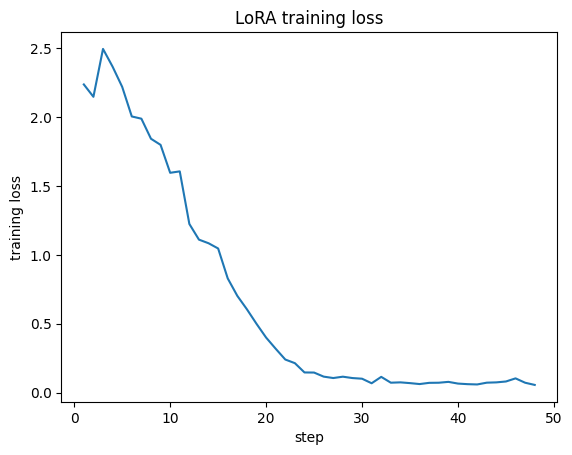

In [ ]:
history = [h for h in trainer.state.log_history if 'loss' in h]
plt.plot([h['step'] for h in history], [h['loss'] for h in history])
plt.xlabel('step'); plt.ylabel('training loss'); plt.title('LoRA training loss')
plt.show()

In [ ]:
ADAPTER = OUT / 'lora_adapter'
model.save_pretrained(str(ADAPTER))
tokenizer.save_pretrained(str(ADAPTER))
print(sorted(p.name for p in ADAPTER.iterdir()))

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/manga_task/outputs/lora_adapter/tokenizer_config.json.


['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'processor_config.json', 'tokenizer.json', 'tokenizer_config.json']


In [ ]:
FastVisionModel.for_inference(model)

run_experiment('C_lora_v2prompt', TRAIN_PROMPT, 'Qwen2-VL-7B 4bit + LoRA, page-by-page prompt v2',
               training='LoRA r=16, 2 epochs, lr 1e-4, page-level, 64 train sequences',
               notes='no cross-page speaker consistency')
pd.read_csv(OUT / 'experiments.csv')

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


C_lora_v2prompt: 0 done, 16 to do


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[1/16] seq_2032620aa4e4ac7f lines per page=[8, 2, 6] (1.2 min)


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[15/16] seq_e8b4f75454f9491f lines per page=[9, 3, 3] (26.2 min)


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[16/16] seq_f7f9d9dbf5b05cb5 lines per page=[7, 6, 9] (27.5 min)
{
  "text_order_score": 0.6047009662796918,
  "balanced_joint_f1": 0.24670106641373796,
  "speaker_accuracy_on_matched": 0.597184474492677,
  "joint_f1": 0.4258997722529184,
  "matched_token_coverage": 0.727460734441136
}



,experiment,pipeline,training,text_order,joint_f1,balanced_joint_f1,speaker_acc_matched,coverage,notes
0,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
1,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A
2,B_prompt_v2,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v2",none (frozen),0.5674,0.3587,0.2202,0.5586,0.6789,excludes SFX/tagline/recap; NARRATION only for...
3,B_prompt_v2_keep1,B_prompt_v2 + keep at most 1 copy of the same ...,none (frozen),0.5671,0.3672,0.2209,0.5567,0.6754,same raw output as B_prompt_v2
4,C_lora_v2prompt,"Qwen2-VL-7B 4bit + LoRA, page-by-page prompt v2","LoRA r=16, 2 epochs, lr 1e-4, page-level, 64 t...",0.6047,0.4259,0.2467,0.5972,0.7275,no cross-page speaker consistency


In [ ]:
print(sorted(p.name for p in (OUT / 'lora_adapter').iterdir()))

['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'processor_config.json', 'tokenizer.json', 'tokenizer_config.json']


In [ ]:
display(repetition_report('C_lora_v2prompt'))
rescore_with_dedupe('C_lora_v2prompt', max_copies=1)
for m in ['text_order_score', 'joint_f1', 'balanced_joint_f1']:
    compare('B_prompt_v2', 'C_lora_v2prompt', m)
bag_vs_order('C_lora_v2prompt')
pd.read_csv(OUT / 'experiments.csv')

C_lora_v2prompt | repeated lines: 75 of 424 | pages cut off: 2


,sequence,page,lines,unique_texts,gold_lines,cut_off,repeated
26,seq_b8b5563330fdc89d,3,54,5,8,True,49
9,seq_84541a1f4b159018,1,19,10,11,False,9
12,seq_952f154fb1505883,1,20,13,14,False,7
30,seq_d749b853cf795b6a,1,11,7,7,False,4
39,seq_de542b63e6b19bc2,1,12,10,7,False,2
25,seq_b8b5563330fdc89d,2,9,8,8,False,1
0,seq_2032620aa4e4ac7f,1,8,7,5,False,1
7,seq_5f9ee35846b7e635,2,6,5,5,False,1


{
  "text_order_score": 0.6130258827933782,
  "balanced_joint_f1": 0.25035877672928525,
  "speaker_accuracy_on_matched": 0.5955531138446073,
  "joint_f1": 0.43051131446898655,
  "matched_token_coverage": 0.7148676867098461
}

text_order_score: C_lora_v2prompt better on 9, worse on 4, about equal on 3 sequences
joint_f1: C_lora_v2prompt better on 12, worse on 4, about equal on 0 sequences
balanced_joint_f1: C_lora_v2prompt better on 8, worse on 8, about equal on 0 sequences
C_lora_v2prompt | pages with text: 48
  order-free word F1: 0.907
  scorer page score : 0.605


,experiment,pipeline,training,text_order,joint_f1,balanced_joint_f1,speaker_acc_matched,coverage,notes
0,A_baseline_v1,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v1",none (frozen),0.5506,0.3246,0.1795,0.4960,0.6571,NaN
1,A2_keep1,A + keep at most 1 copy of the same text per page,none (frozen),0.5645,0.3376,0.1811,0.4969,0.6561,same raw output as A
2,B_prompt_v2,"Qwen2-VL-7B 4bit, page-by-page JSON prompt v2",none (frozen),0.5674,0.3587,0.2202,0.5586,0.6789,excludes SFX/tagline/recap; NARRATION only for...
3,B_prompt_v2_keep1,B_prompt_v2 + keep at most 1 copy of the same ...,none (frozen),0.5671,0.3672,0.2209,0.5567,0.6754,same raw output as B_prompt_v2
4,C_lora_v2prompt,"Qwen2-VL-7B 4bit + LoRA, page-by-page prompt v2","LoRA r=16, 2 epochs, lr 1e-4, page-level, 64 t...",0.6047,0.4259,0.2467,0.5972,0.7275,no cross-page speaker consistency
5,C_lora_v2prompt_keep1,C_lora_v2prompt + keep at most 1 copy of the s...,same as C_lora_v2prompt,0.6130,0.4305,0.2504,0.5956,0.7149,same raw output as C_lora_v2prompt


In [ ]:
oracle_rows = [{'sequence_id': sid, 'pages': [relabel_page(p) for p in labels[sid]]} for sid in val_ids]
write_jsonl(OUT / 'oracle_pagelocal_predictions.jsonl', oracle_rows)
run_scorer(OUT / 'val_labels.jsonl', OUT / 'oracle_pagelocal_predictions.jsonl',
           OUT / 'oracle_pagelocal_scores.json')

{
  "text_order_score": 1.0,
  "balanced_joint_f1": 0.5895662775142462,
  "speaker_accuracy_on_matched": 0.7425212591614799,
  "joint_f1": 0.7425212591614799,
  "matched_token_coverage": 1.0
}



In [ ]:
m = json.load(open(OUT / 'oracle_pagelocal_scores.json'))['macro']
with open(OUT / 'experiments.csv', 'a', newline='', encoding='utf-8') as f:
    csv.writer(f).writerow(['ORACLE_pagelocal', 'gold text + gold speakers, labels renamed per page', 'n/a (reference)',
                            round(m['text_order_score'], 4), round(m['joint_f1'], 4), round(m['balanced_joint_f1'], 4),
                            round(m['speaker_accuracy_on_matched'], 4), round(m['matched_token_coverage'], 4),
                            'ceiling of any page-by-page system'])

In [ ]:
# 1. Peak GPU memory since training started (the training cell reset the counter right before it began)
print('peak VRAM (GB):', round(torch.cuda.max_memory_allocated() / 1024**3, 2))

# 2. Single-word lines in C, after removing repeats
def one_plain_word(text):
    return len(text.split()) == 1 and text.isalpha()

preds_k = {}
for l in open(OUT / 'C_lora_v2prompt_keep1_predictions.jsonl'):
    r = json.loads(l)
    preds_k[r['sequence_id']] = r['pages']

found = [(sid[-6:], i + 1, line['speaker'], line['text'])
         for sid, pages in preds_k.items() for i, page in enumerate(pages)
         for line in page if one_plain_word(line['text'])]
print('single-word lines in C (deduped):', len(found))
for f in found:
    print(f)

# 3. Is the text problem order or the words themselves, for the frozen model B
bag_vs_order('B_prompt_v2')

peak VRAM (GB): 7.79
single-word lines in C (deduped): 23
('e4ac7f', 1, 'character1', 'SNAP')
('e4ac7f', 3, 'character6', 'CLACK')
('e99417', 3, 'character1', 'CHOMP')
('e99417', 3, 'character1', 'GULP')
('e99417', 3, 'character1', 'THUMP')
('e99417', 3, 'character1', 'KRIK')
('e99417', 3, 'character1', 'HEH')
('e99417', 3, 'character1', 'FSHH')
('159018', 1, 'character1', 'BADUM')
('159018', 1, 'character1', 'KNOCK')
('159018', 2, 'character1', 'SHOOF')
('159018', 3, 'character1', 'FWIP')
('33b97c', 1, 'character1', 'HI')
('fdc89d', 3, 'character1', 'SKRSH')
('795b6a', 3, 'character2', 'BAM')
('f9122d', 3, 'character1', 'WHIMPER')
('f9122d', 3, 'character1', 'P')
('c91090', 3, 'character1', 'HEH')
('c91090', 3, 'character1', 'CASP')
('b19bc2', 1, 'character1', 'GOLOP')
('b19bc2', 2, 'character1', 'ASH')
('b19bc2', 3, 'character1', 'KRAAA')
('b05cb5', 2, 'character1', 'KREAK')
B_prompt_v2 | pages with text: 48
  order-free word F1: 0.925
  scorer page score : 0.567


In [ ]:
import shutil

shutil.copy(OUT / 'A_baseline_v1_predictions.jsonl', OUT / 'baseline_predictions.jsonl')
shutil.copy(OUT / 'C_lora_v2prompt_predictions.jsonl', OUT / 'lora_predictions.jsonl')
shutil.copy(OUT / 'A_baseline_v1_scores.json', OUT / 'baseline_scores.json')
shutil.copy(OUT / 'C_lora_v2prompt_scores.json', OUT / 'lora_scores.json')
print(sorted(p.name for p in OUT.iterdir() if p.name.endswith(('predictions.jsonl', 'scores.json'))))

['A2_keep1_predictions.jsonl', 'A2_keep1_scores.json', 'A_baseline_v1_predictions.jsonl', 'A_baseline_v1_scores.json', 'B_prompt_v2_keep1_predictions.jsonl', 'B_prompt_v2_keep1_scores.json', 'B_prompt_v2_predictions.jsonl', 'B_prompt_v2_scores.json', 'C_lora_v2prompt_keep1_predictions.jsonl', 'C_lora_v2prompt_keep1_scores.json', 'C_lora_v2prompt_predictions.jsonl', 'C_lora_v2prompt_scores.json', 'baseline_predictions.jsonl', 'baseline_scores.json', 'lora_predictions.jsonl', 'lora_scores.json', 'oracle_pagelocal_predictions.jsonl', 'oracle_pagelocal_scores.json']


#speaker consistency

In [ ]:
exp = 'C_lora_v2prompt_keep1'
sc = json.load(open(OUT / f'{exp}_scores.json'))['sequences']
gaps = []
for sid, pages in preds_k.items():
    for i in range(3):
        b = bag_f1(labels[sid][i], pages[i])
        if b is None:
            continue
        gaps.append((b - sc[sid]['page_text_scores'][str(i + 1)], sid, i))
gaps.sort(reverse=True)

for gap, sid, i in gaps[:3]:
    print(f'===== {sid} page {i + 1} | word overlap minus page score = {gap:.2f}')
    print('GOLD, in order:')
    for k, x in enumerate(labels[sid][i], 1):
        print(f'  {k}.', x['text'][:60])
    print('PREDICTED, in order:')
    for k, x in enumerate(preds_k[sid][i], 1):
        print(f'  {k}.', x['text'][:60])

===== seq_b8b5563330fdc89d page 2 | word overlap minus page score = 0.77
GOLD, in order:
  1. DON'T CONCERN YOURSELF, SOLDIER... IT'S ALWAYS LIKE THIS IN 
  2. OH, MY DARLIN' CLE-MEN-TINE...
  3. OH, MY DARLIN', OH, MY DARLIN', OH, MY DARLIN' CLE-MEN-TINE.
  4. MAN, YOU EVER NOTICE THE WAY YOU REPEAT YOURSELF?
  5. I DON'T KNOW THE REST OF THE SONG, SERGEANT.
  6. AHHH... JUST TWO MORE DAYS AND I KISS THIS MUDHOLE GOODBYE.
  7. WHERE YOU FROM, KID?
  8. PHILADELPHIA, SARGE.
PREDICTED, in order:
  1. MAN, YOU EVER NOTICE THE WAY YOU REPEAT YOURSELF?
  2. I DON'T KNOW THE REST OF THE SONG, SERGEANT.
  3. PHILA-DELPHIA, SARGE.
  4. WHERE YOU FROM, KID?
  5. AHHH... JUST TWO MORE DAYS AND I KISS THIS MUDHOLE GOODBYE.
  6. DON'T CONCERN YOURSELF, SOLDIER... IT'S ALWAYS LIKE THIS IN 
  7. OH, MY DARLIN', OH, MY DARLIN', OH, MY DARLIN' CLE-MEN-TINE.
  8. OH, MY DARLIN' CLE-MEN-TINE...
===== seq_f7f9d9dbf5b05cb5 page 3 | word overlap minus page score = 0.73
GOLD, in order:
  1. YOU'RE CURSED, 

In [ ]:
from difflib import SequenceMatcher
from scipy.stats import kendalltau

def page_tau(gold_page, pred_page):
    positions = []
    for line in pred_page:                          # which gold line does each predicted line match?
        best, best_score = None, 0.7                # needs at least 70% text similarity
        for g, gl in enumerate(gold_page):
            s = SequenceMatcher(None, line['text'].lower(), gl['text'].lower()).ratio()
            if s > best_score:
                best, best_score = g, s
        if best is not None:
            positions.append(best)
    positions = list(dict.fromkeys(positions))      # drop duplicates, keep the first
    if len(positions) < 3:
        return None
    return kendalltau(range(len(positions)), positions)[0]

taus = []
for sid, pages in preds_k.items():
    for i in range(3):
        t = page_tau(labels[sid][i], pages[i])
        if t is not None:
            taus.append(t)

print('pages measured:', len(taus), '| mean tau:', round(sum(taus) / len(taus), 2))
print('almost right order (tau > 0.8):', sum(t > 0.8 for t in taus))
print('mixed (-0.5 to 0.8):', sum(-0.5 <= t <= 0.8 for t in taus))
print('mostly reversed (tau < -0.5):', sum(t < -0.5 for t in taus))

pages measured: 42 | mean tau: 0.57
almost right order (tau > 0.8): 14
mixed (-0.5 to 0.8): 26
mostly reversed (tau < -0.5): 2


In [ ]:
rev_rows = [{'sequence_id': sid, 'pages': [list(reversed(p)) for p in pages]}
            for sid, pages in preds_k.items()]
write_jsonl(OUT / 'diag_reversed_predictions.jsonl', rev_rows)
run_scorer(OUT / 'val_labels.jsonl', OUT / 'diag_reversed_predictions.jsonl',
           OUT / 'diag_reversed_scores.json')

{
  "text_order_score": 0.38149063664306754,
  "balanced_joint_f1": 0.1664537196906708,
  "speaker_accuracy_on_matched": 0.6329690201452873,
  "joint_f1": 0.2833144215167045,
  "matched_token_coverage": 0.4577859772580308
}



In [ ]:
#test predictions
FINAL_PROMPT = PROMPT_V2          # the prompt C was trained with
FastVisionModel.for_inference(model)

def dedupe_page(page):
    seen, kept = set(), []
    for line in page:
        if line['text'] not in seen:
            seen.add(line['text'])
            kept.append(line)
    return kept

final_path = OUT / 'final_predictions.jsonl'
# final_path.unlink(missing_ok=True)      # uncomment to start from scratch

done = set()
if final_path.exists():
    done = {json.loads(l)['sequence_id'] for l in open(final_path) if l.strip()}

for sid in test_ids:
    if sid in done:
        continue
    pages, raws = process_sequence(seq_by_id[sid], FINAL_PROMPT)
    pages = [dedupe_page(p) for p in pages]
    with open(final_path, 'a', encoding='utf-8') as f:
        f.write(json.dumps({'sequence_id': sid, 'pages': pages}, ensure_ascii=False) + '\n')
    print(sid, [len(p) for p in pages])
print('sequences written:', sum(1 for _ in open(final_path)))

Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

seq_14469aeb38963085 [10, 12, 4]


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


seq_e9ffbb64217c2fed [11, 15, 7]


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

seq_e456a0394af99570 [7, 3, 3]


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


seq_c5622aca7487a661 [1, 6, 4]


Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=1024) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


seq_75aeca6c7131544b [1, 5, 3]
sequences written: 15


In [ ]:
def validate_predictions(path, expected_ids):
    seen = []
    for n, line in enumerate(open(path, encoding='utf-8'), 1):
        row = json.loads(line)                                           # valid JSON
        assert set(row) == {'sequence_id', 'pages'}, f'line {n}: extra or missing keys'
        assert isinstance(row['pages'], list) and len(row['pages']) == 3, f'line {n}: need exactly 3 pages'
        for page in row['pages']:
            assert isinstance(page, list), f'line {n}: a page is not a list'
            for item in page:
                assert set(item) == {'speaker', 'text'}, f'line {n}: bad item keys'
                assert isinstance(item['speaker'], str) and item['speaker'].strip(), f'line {n}: empty speaker'
                assert isinstance(item['text'], str) and item['text'].strip(), f'line {n}: empty text'
        seen.append(row['sequence_id'])
    assert sorted(seen) == sorted(expected_ids), 'sequence ids do not match the expected ids'
    assert len(seen) == len(set(seen)), 'duplicate sequence ids'
    print('OK:', len(seen), 'sequences')

validate_predictions(OUT / 'final_predictions.jsonl', test_ids)
validate_predictions(OUT / 'lora_predictions.jsonl', val_ids)     # same check on the validation predictions

OK: 15 sequences
OK: 16 sequences


In [ ]:
import platform, importlib.metadata as md_

packages = ['torch', 'transformers', 'unsloth', 'peft', 'trl', 'accelerate', 'bitsandbytes', 'datasets', 'pillow']
lines = []
for p in packages:
    try:
        lines.append(f'{p}=={md_.version(p)}')
    except Exception:
        lines.append(f'# {p} not found')
(OUT / 'requirements.txt').write_text('\n'.join(lines) + '\n')

info = {
    'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(0),
    'base_model': 'unsloth/Qwen2-VL-7B-Instruct (4-bit)',
    'split_seed': SEED,
    'lora': {'r': 16, 'alpha': 16, 'dropout': 0, 'vision_layers': False, 'language_layers': True},
    'training': {'batch_size': 1, 'grad_accum': 8, 'epochs': 2, 'lr': 1e-4, 'max_length': 4096},
    'inference': {'do_sample': False, 'max_new_tokens': 1024},
}
json.dump(info, open(OUT / 'run_info.json', 'w'), indent=2)
print(open(OUT / 'requirements.txt').read())

torch==2.11.0+cu130
transformers==5.5.0
unsloth==2026.9.14
peft==0.21.0
trl==0.24.0
accelerate==1.15.0
bitsandbytes==0.50.2
datasets==4.3.0
pillow==11.3.0



In [ ]:
#reloading save adapter
from unsloth import FastVisionModel
import torch

model, tokenizer = FastVisionModel.from_pretrained(
    '/content/drive/MyDrive/manga_task/outputs/lora_adapter',
    load_in_4bit=True,
)
FastVisionModel.for_inference(model)

In [ ]:
import shutil
shutil.copy(OUT / 'final_predictions.jsonl', OUT / 'final_predictions_v1.jsonl')
print(sorted(p.name for p in OUT.iterdir()))

from google.colab import files
files.download(str(OUT / 'final_predictions.jsonl'))

['A2_keep1_predictions.jsonl', 'A2_keep1_scores.json', 'A_baseline_v1_predictions.jsonl', 'A_baseline_v1_raw.jsonl', 'A_baseline_v1_scores.json', 'B_prompt_v2_keep1_predictions.jsonl', 'B_prompt_v2_keep1_scores.json', 'B_prompt_v2_predictions.jsonl', 'B_prompt_v2_raw.jsonl', 'B_prompt_v2_scores.json', 'C_lora_v2prompt_keep1_predictions.jsonl', 'C_lora_v2prompt_keep1_scores.json', 'C_lora_v2prompt_predictions.jsonl', 'C_lora_v2prompt_raw.jsonl', 'C_lora_v2prompt_scores.json', 'baseline_predictions.jsonl', 'baseline_scores.json', 'checkpoints', 'diag_reversed_predictions.jsonl', 'diag_reversed_scores.json', 'experiments.csv', 'final_predictions.jsonl', 'final_predictions_v1.jsonl', 'lora_adapter', 'lora_predictions.jsonl', 'lora_scores.json', 'oracle_pagelocal_predictions.jsonl', 'oracle_pagelocal_scores.json', 'prompts', 'requirements.txt', 'run_info.json', 'split.json', 'train_labels.jsonl', 'val_labels.jsonl']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>